<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-11, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [1]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [2]:
# Load the big dataset Train.big.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'
url

df = pd.read_csv(
    url,
    usecols=range(15),
    nrows=10_000,
)

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.476,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
9995,9995,train_9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,9996,train_9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,9997,train_9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,9998,train_9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,9999,train_9999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data Cleaning


### Summary Meta-Data

In [5]:
# Shape of the dataframe
df.shape

(10000, 15)

In [6]:
# Size of the dataframe
df.size

150000

In [7]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   ID_code     10000 non-null  object 
 2   target      1686 non-null   float64
 3   var_0       1686 non-null   float64
 4   var_1       1686 non-null   float64
 5   var_2       1686 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       1686 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       1686 non-null   float64
 11  var_8       1686 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
dtypes: float64(13), int64(1), object(1)
memory usage: 1.1+ MB


### Summary Statistics

In [8]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
count,10000.00000,1686.000000,1686.000000,1686.000000,1686.000000,0.0,1686.000000,0.0,0.0,1686.000000,1686.000000,0.0,0.0,0.0
mean,4999.50000,0.098458,7.493109,15.840630,12.667966,NaN,-0.461214,NaN,NaN,1.276329,6.812313,NaN,NaN,NaN
std,2886.89568,0.298021,3.090435,3.086651,4.187706,NaN,6.014515,NaN,NaN,5.103567,0.374905,NaN,NaN,NaN
min,0.00000,0.000000,-0.101600,7.700200,3.218700,NaN,-16.855000,NaN,NaN,-11.731000,5.688300,NaN,NaN,NaN
25%,2499.75000,0.000000,5.174825,13.739200,9.601600,NaN,-4.893675,NaN,NaN,-2.458950,6.559500,NaN,NaN,NaN
50%,4999.50000,0.000000,7.379350,15.992700,12.478250,NaN,-0.190200,NaN,NaN,1.080350,6.795350,NaN,NaN,NaN
75%,7499.25000,0.000000,9.708875,18.155675,15.725050,NaN,3.730575,NaN,NaN,5.107175,7.071325,NaN,NaN,NaN
max,9999.00000,1.000000,16.716500,23.971700,24.828500,NaN,15.973100,NaN,NaN,17.441800,7.877900,NaN,NaN,NaN


### Data Types

In [9]:
# Display data types of columns
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,float64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


### Nulls and Identifier Columns
Imputation required on account of the nulls.

#### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

#### Target Value Counts

Binary numerical classification and nulls are present.

In [10]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
NaN,8314
0.0,1520
1.0,166


#### Normalize The Data

In [11]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
NaN,0.8314
0.0,0.1520
1.0,0.0166


#### Nulls

In [12]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
var_3,10000
var_6,10000
var_11,10000
var_9,10000
var_10,10000
var_5,10000
var_0,8314
target,8314
var_4,8314
var_2,8314


#### Feature Columns

In [13]:
# Normalize the data to see proportion of nulls on features
df.drop(columns=['target']).isnull().mean().sort_values(ascending=False)

,0
var_3,1.0000
var_11,1.0000
var_9,1.0000
var_10,1.0000
var_6,1.0000
var_5,1.0000
var_0,0.8314
var_4,0.8314
var_2,0.8314
var_1,0.8314


#### Identifier Columns

In [14]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,10000
ID_code,10000
var_4,1678
var_7,1677
var_0,1677
var_2,1672
var_1,1663
var_8,1596
target,2
var_3,0


### Backup #1

In [15]:
# Make backup
df_bak = df.copy()

In [16]:
# Restore from backup
df = df_bak.copy()

### Recommendations

#### Identifier Columns

Exclude columns 'Unnamed: 0' and 'ID_code'

In [17]:
# Drop the 'Unnamed: 0' and 'ID_code' columns
df = df.drop(columns=['Unnamed: 0','ID_code'])

In [18]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,0.0,4.1463,20.3755,14.8105,NaN,6.0432,NaN,NaN,1.2462,6.5467,NaN,NaN,NaN
9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Target Column with Null Counts

Remove rows with unknown target values

In [19]:
df = df.dropna(subset=['target'])

In [20]:
# Verify
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11
3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,-1.9254,6.4760,NaN,NaN,NaN
5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,-6.4882,6.0821,NaN,NaN,NaN
11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,4.0501,5.8144,NaN,NaN,NaN
15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,-5.4904,6.6670,NaN,NaN,NaN
19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,8.8477,6.8045,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,NaN,-4.5570,NaN,NaN,-2.0199,6.4613,NaN,NaN,NaN
9982,0.0,7.4992,12.3931,15.6143,NaN,3.9159,NaN,NaN,-6.4257,6.4960,NaN,NaN,NaN
9983,0.0,3.6195,11.1681,6.0020,NaN,2.7570,NaN,NaN,-1.3041,7.3073,NaN,NaN,NaN
9993,0.0,6.6722,17.1154,9.2696,NaN,8.2625,NaN,NaN,4.0066,6.6464,NaN,NaN,NaN


#### Feature Columns with High Null Counts

Investigate usefullness and consider dropping or imputing

In [21]:
#See null counts in each of the var columns (exlude the identifier and target columns)
df.isnull().sum().sort_values(ascending=False)

,0
var_3,1686
var_9,1686
var_10,1686
var_6,1686
var_5,1686
var_11,1686
var_1,0
var_0,0
target,0
var_2,0


In [22]:
# Drop columns that contain exactly all null values (1686 nulls)
df = df.dropna(axis=1, thresh=1)

In [23]:
# Verify
df.isnull().sum().sort_values(ascending=False)

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0


#### Feature Columns with Low Null Counts

Consider some row removal or imputation

In [24]:
# See if imputation needed for any low null counts in feature columns
# Null counts all at zero now, so no imputation needed
df.isnull().sum()

,0
target,0
var_0,0
var_1,0
var_2,0
var_4,0
var_7,0
var_8,0


#### Feature Columns with Medium Null Counts

Investigate before removing rows

In [25]:
# No imputation needed

### Backup #2

In [26]:
# Make 2nd backup
df_bak_2 = df.copy()

In [27]:
# Restore from 2nd backup
df = df_bak_2.copy()

### Keep Only the Target and Features

In [28]:
# Select the target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [29]:
# Verify dataframe is the same
df

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [30]:
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
9978,0.0
9982,0.0
9983,0.0
9993,0.0


In [31]:
features

,var_0,var_1,var_2,var_4,var_7,var_8
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...
9978,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [32]:
# Make a backup
df_bak_3 = df.copy()

In [33]:
# Restore from backup
df = df_bak_3.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

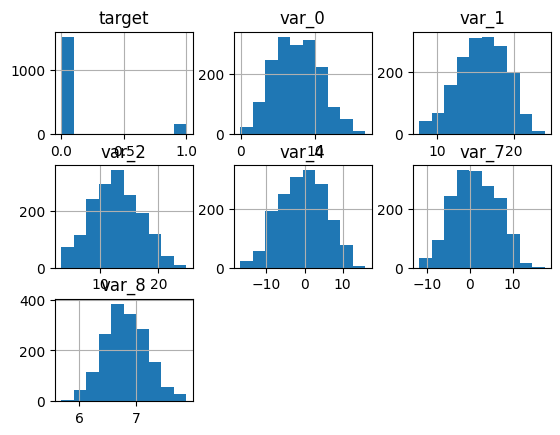

In [34]:
# Display a histogram
df.hist() ;

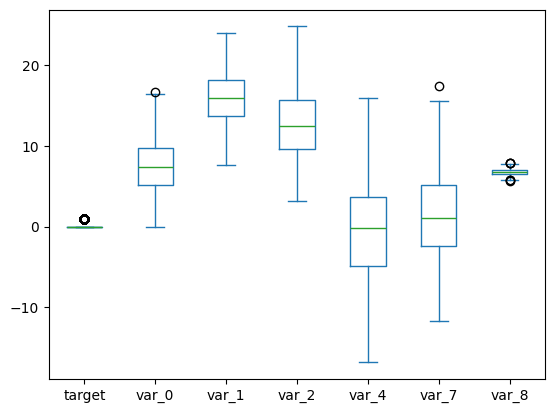

In [35]:
# Display a box and whisker plot
df.plot(kind='box') ;

### Correlation: Independence of Features

In [36]:
# Calculate a correlation matrix
corr_mat = features.corr()

corr_mat

,var_0,var_1,var_2,var_4,var_7,var_8
var_0,1.000000,0.005254,-0.008940,-0.032564,0.019145,-0.004555
var_1,0.005254,1.000000,-0.006304,0.027493,0.033324,0.005790
var_2,-0.008940,-0.006304,1.000000,0.032350,0.015287,-0.007869
var_4,-0.032564,0.027493,0.032350,1.000000,0.016244,-0.016298
var_7,0.019145,0.033324,0.015287,0.016244,1.000000,-0.031002
var_8,-0.004555,0.005790,-0.007869,-0.016298,-0.031002,1.000000


Text(0.5, 23.52222222222222, 'Features')

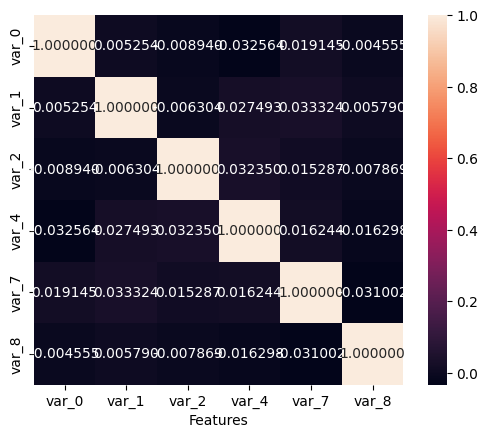

In [37]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [38]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Two data sets with target and features

In [39]:
# Split data frame into target and features
# Already split above

In [40]:
# Display the target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
9978,0.0
9982,0.0
9983,0.0
9993,0.0


In [41]:
# Display the features
features

,var_0,var_1,var_2,var_4,var_7,var_8
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...
9978,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [42]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [43]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [44]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(1264, 6)
<class 'pandas.core.frame.DataFrame'>
(422, 6)
<class 'pandas.core.frame.DataFrame'>
(1264,)
<class 'pandas.core.series.Series'>
(422,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [45]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [46]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

#### Calculate and report the accuracy.

In [47]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

91.23222748815166

#### Present a confusion matrix and heatmap

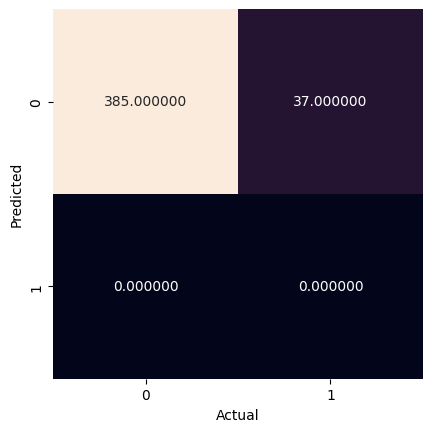

In [48]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [49]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95       385
         1.0       0.00      0.00      0.00        37

    accuracy                           0.91       422
   macro avg       0.46      0.50      0.48       422
weighted avg       0.83      0.91      0.87       422



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Multiple Cross-Validation (CV)

In [50]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
    )

    # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.accuracy_score(y_test, pred_results)

results

array([0.87914692, 0.90995261, 0.87440758, 0.87440758, 0.90758294,
       0.91232227, 0.90047393, 0.88388626, 0.91706161, 0.90995261,
       0.92654028, 0.8957346 , 0.86966825, 0.90995261, 0.90758294,
       0.9028436 , 0.90047393, 0.88625592, 0.91232227, 0.92180095,
       0.91469194, 0.91469194, 0.89810427, 0.93127962, 0.9028436 ,
       0.89336493, 0.8957346 , 0.9028436 , 0.91232227, 0.89336493,
       0.89099526, 0.89099526, 0.91469194, 0.91232227, 0.88151659,
       0.93364929, 0.91232227, 0.9028436 , 0.92180095, 0.90047393,
       0.9028436 , 0.91232227, 0.9028436 , 0.90758294, 0.9028436 ,
       0.90758294, 0.89810427, 0.8957346 , 0.91469194, 0.90521327,
       0.88388626, 0.9028436 , 0.89336493, 0.89336493, 0.89810427,
       0.91943128, 0.91706161, 0.88625592, 0.89810427, 0.90995261,
       0.88151659, 0.92180095, 0.89099526, 0.90047393, 0.89810427,
       0.9028436 , 0.91469194, 0.9028436 , 0.88862559, 0.87914692,
       0.88862559, 0.86729858, 0.87914692, 0.9028436 , 0.89810

### Accuracy Comparison
Accuracies are both 91% for single and multi CVs

In [51]:
# Compare the accuracies by creating variables for each
acc_single_cv = acc
acc_multi_cv = results[i]

display('Single CV:', acc_single_cv)
display('Multi CV:', acc_multi_cv)

'Single CV:'

0.9123222748815166

'Multi CV:'

np.float64(0.8886255924170616)

### Balance Dataset

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).

#### Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions.

In [52]:
# Display value counts of the target
df['target'].value_counts()

,count
target,
0.0,1520
1.0,166


In [53]:
# Place minority class in one dataframe
successful_df

,target,var_0,var_1,var_2,var_4,var_7,var_8
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025
...,...,...,...,...,...,...,...
9704,1.0,3.8035,15.8842,9.7204,1.6659,9.4225,7.2885
9721,1.0,8.0545,13.9124,14.7748,-6.4229,9.2862,6.4995
9760,1.0,8.6481,15.4023,6.3946,-5.2774,8.7673,7.7839
9832,1.0,11.4846,18.8724,8.7859,-1.6645,3.9079,6.6286


In [54]:
# Put majority class into its own dataframe (done above)
unsuccessful_df

,target,var_0,var_1,var_2,var_4,var_7,var_8
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...,...
9978,0.0,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,0.0,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,0.0,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,0.0,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [55]:
# Create downsample of majority class in another data frame
majority_downsampled = unsuccessful_df.sample(
    n=len(successful_df),
    random_state=42
)

# Display the downsample to verify
print("Minority class:")
print(successful_df['target'].value_counts())

print("Downsampled majority class:")
print(majority_downsampled['target'].value_counts())

Minority class:
target
1.0    166
Name: count, dtype: int64
Downsampled majority class:
target
0.0    166
Name: count, dtype: int64


In [56]:
# Combine the dataframes
balanced_df = pd.concat([successful_df, majority_downsampled])

# Reset the index
balanced_df = balanced_df.reset_index(drop=True)

In [57]:
# Verify target counts
balanced_df['target'].value_counts()

,count
target,
1.0,166
0.0,166


#### Backup #3

In [58]:
# Create 3rd backup
df_bak_3 = df.copy()

In [59]:
# Restore from backup
df = df_bak_3.copy()

#### Repeat Multi Cross-Validation

In [60]:
# Split data frame into target and features
# Already set up above

In [61]:
# Display the target
target

,target
3,0.0
5,0.0
11,0.0
15,0.0
19,0.0
...,...
9978,0.0
9982,0.0
9983,0.0
9993,0.0


In [62]:
# Display the features
features

,var_0,var_1,var_2,var_4,var_7,var_8
3,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760
5,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821
11,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144
15,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670
19,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045
...,...,...,...,...,...,...
9978,3.7065,12.2215,12.0781,-4.5570,-2.0199,6.4613
9982,7.4992,12.3931,15.6143,3.9159,-6.4257,6.4960
9983,3.6195,11.1681,6.0020,2.7570,-1.3041,7.3073
9993,6.6722,17.1154,9.2696,8.2625,4.0066,6.6464


In [63]:
# Multiple CV loop
n = 100
balanced_df_results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
    )

   # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    balanced_df_results[i] = metrics.accuracy_score(y_test, pred_results)

balanced_df_results

array([0.89336493, 0.9028436 , 0.9028436 , 0.89336493, 0.9028436 ,
       0.92654028, 0.92654028, 0.90758294, 0.89336493, 0.9028436 ,
       0.89099526, 0.89336493, 0.91706161, 0.91469194, 0.90047393,
       0.87440758, 0.89099526, 0.8957346 , 0.8957346 , 0.9028436 ,
       0.89810427, 0.90758294, 0.9028436 , 0.90521327, 0.9028436 ,
       0.90758294, 0.90047393, 0.91232227, 0.90758294, 0.91232227,
       0.9028436 , 0.91706161, 0.8957346 , 0.90047393, 0.90758294,
       0.91943128, 0.90521327, 0.89099526, 0.87203791, 0.9028436 ,
       0.87914692, 0.88625592, 0.89810427, 0.87914692, 0.92180095,
       0.91706161, 0.90047393, 0.89099526, 0.89099526, 0.91943128,
       0.8957346 , 0.89336493, 0.90758294, 0.91232227, 0.90758294,
       0.88625592, 0.90047393, 0.90521327, 0.89810427, 0.90047393,
       0.91232227, 0.89336493, 0.89099526, 0.87677725, 0.91943128,
       0.9028436 , 0.9028436 , 0.90758294, 0.90521327, 0.90995261,
       0.8957346 , 0.91943128, 0.91706161, 0.90758294, 0.90758

#### Mean accuracy for balanced dataset

In [64]:
# Report what your mean accuracy for this balanced data set
display(balanced_df_results[i])

np.float64(0.9075829383886256)

#### Histogram of the accuracy scores

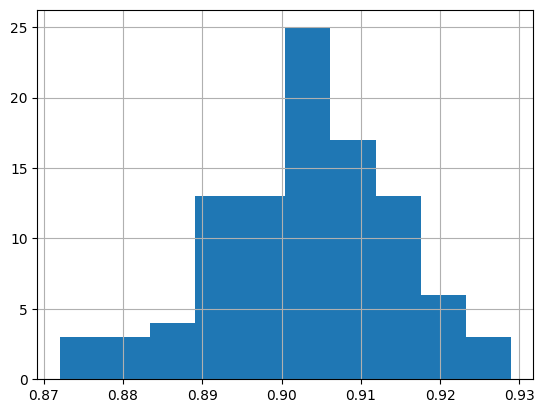

In [65]:
pd.Series(balanced_df_results).hist() ;

What do you notice about the distribution of accuracy scores?

There is a positive skew.

#### Confusion Matrix and Heatmap

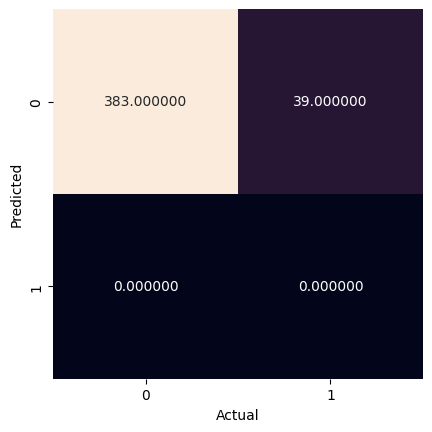

In [66]:
mat =  metrics.confusion_matrix(
    y_test,
    pred_results,
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Classification Report

In [67]:
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.91      1.00      0.95       383
         1.0       0.00      0.00      0.00        39

    accuracy                           0.91       422
   macro avg       0.45      0.50      0.48       422
weighted avg       0.82      0.91      0.86       422



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


What do you notice? That is, how do the different metrics compare to each other?

## Data Visualization/Communication of Results


### Data Visualization

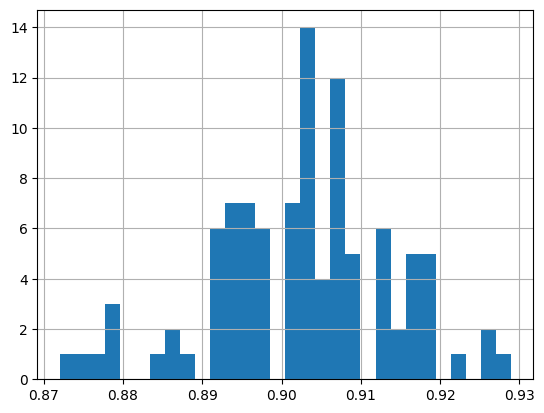

In [68]:
# Display a histagram of the results
pd.Series(balanced_df_results).hist(bins=30) ;

## Conclusion

### Communicate Results

- In Pass-11, using the big data set, all rows/columns, imputing out high null rows/columns, and balancing the dataset:
- Accuracy came out to 91% (same as previous pass)
- Not great at predicting no-transactions
- Excellent at predicting a successful transaction
- Low (zero) false positive (we predict customer will make a transaction but customer does not)
- Medium false negatives (we predict customer will not make a transaction but customer does)

### Future work

?